In [1]:
# Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import load_model



2024-10-24 04:32:47.760673: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-24 04:32:47.760784: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-24 04:32:47.935378: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
df= pd.read_csv('/kaggle/input/fish-growth/IoTPond2.csv')
df

,created_at,entry_id,Temperature (C),Turbidity (NTU),Dissolved Oxygen(g/ml),PH,Ammonia(g/ml),Nitrate(g/ml),Population,Fish_Length (cm),Fish_Weight (g)
0,2021-06-19 00:00:05 CET,1889,24.8750,100,4.505,8.43365,0.38000,193,50,6.96,3.36
1,2021-06-19 00:01:02 CET,1890,24.9375,100,6.601,8.43818,0.38000,194,50,6.96,3.36
2,2021-06-19 00:01:22 CET,1891,24.8750,100,15.797,8.42457,0.38000,192,50,6.96,3.36
3,2021-06-19 00:01:44 CET,1892,24.9375,100,5.046,8.43365,0.38000,193,50,6.96,3.36
4,2021-06-19 00:02:07 CET,1893,24.9375,100,38.407,8.40641,0.38000,192,50,6.96,3.36
...,...,...,...,...,...,...,...,...,...,...,...
172244,2021-10-31 04:31:10 CET,269368,26.0625,52,8.094,-1.83008,57135.59766,981,50,35.39,394.66
172245,2021-10-31 04:31:58 CET,269369,26.1250,54,10.234,-1.83462,47314.63672,979,50,35.39,394.66
172246,2021-10-31 04:32:19 CET,269370,26.0625,54,4.904,-1.82554,54835.34375,979,50,35.39,394.66
172247,2021-10-31 04:32:40 CET,269371,26.0625,53,8.064,-1.83916,72657.05469,979,50,35.39,394.66


In [3]:
df = df.drop(["entry_id", "Population", "Fish_Length (cm)"], axis=1)
df = df.rename(columns={"created_at":"Collected_Time", "Temperature (C)": "Temp_(C)", "Turbidity (NTU)": "Turb_(NTU)", 
                        "Dissolved Oxygen(g/ml)":"DO_(g/ml)", "Ammonia(g/ml)":"Ammonia_(g/ml)", 
                        "Nitrate(g/ml)":"Nitrate_(g/ml)", "Fish_Weight (g)":"Fish_Weight_(g)"})
df = df.dropna().reset_index(drop=True)
df = df.set_index('Collected_Time')

df

,Temp_(C),Turb_(NTU),DO_(g/ml),PH,Ammonia_(g/ml),Nitrate_(g/ml),Fish_Weight_(g)
Collected_Time,,,,,,,
2021-06-19 00:00:05 CET,24.8750,100,4.505,8.43365,0.38000,193,3.36
2021-06-19 00:01:02 CET,24.9375,100,6.601,8.43818,0.38000,194,3.36
2021-06-19 00:01:22 CET,24.8750,100,15.797,8.42457,0.38000,192,3.36
2021-06-19 00:01:44 CET,24.9375,100,5.046,8.43365,0.38000,193,3.36
2021-06-19 00:02:07 CET,24.9375,100,38.407,8.40641,0.38000,192,3.36
...,...,...,...,...,...,...,...
2021-10-31 04:31:10 CET,26.0625,52,8.094,-1.83008,57135.59766,981,394.66
2021-10-31 04:31:58 CET,26.1250,54,10.234,-1.83462,47314.63672,979,394.66
2021-10-31 04:32:19 CET,26.0625,54,4.904,-1.82554,54835.34375,979,394.66


In [4]:
# Scale the data
input_feature = df.iloc[:, :].to_numpy()
target_feature = df.iloc[:, -1:].to_numpy()

input_scaler = StandardScaler().fit(input_feature)
output_scaler = StandardScaler().fit(target_feature)

input_feature_scaled = input_scaler.transform(input_feature)
target_feature_scaled = output_scaler.transform(target_feature)
# in_scld = pd.DataFrame(input_feature_scaled, columns = df.columns)
# out_scld = pd.DataFrame(target_feature_scaled, columns = df.columns[-1:])


In [5]:
# Split the data into train, eval, and test sets
train_size = int(0.8 * len(df))
eval_size = int(0.05 * len(df))
test_size = len(df) - train_size

n_steps = 134

# Create training data
X_train, y_train = [], []
for i in range(n_steps, train_size):
    X_train.append(input_feature_scaled[i-n_steps:i, :])
    y_train.append(target_feature_scaled[i, :])
X_train, y_train = np.array(X_train), np.array(y_train)

# Create validation data
X_val, y_val = [], []
for i in range(train_size, train_size+eval_size):
    X_val.append(input_feature_scaled[i-n_steps:i, :])
    y_val.append(target_feature_scaled[i, :])
X_val, y_val = np.array(X_val), np.array(y_val)

# Create test data
X_test, y_test = [], []
for i in range(len(df)-test_size, len(df)-n_steps):
    X_test.append(input_feature_scaled[i-n_steps:i, :])
    y_test.append(target_feature_scaled[i, :])
X_test, y_test = np.array(X_test), np.array(y_test)

print(X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape)

(137593, 134, 7) (137593, 1) (8607, 134, 7) (8607, 1) (34298, 134, 7) (34298, 1)


### Load GRU Model

In [6]:
model_lstm = load_model('/kaggle/input/rnnmodel/RNNLSTM4.h5')

In [7]:
predictions = model_lstm.predict(X_test)
predictions = output_scaler.inverse_transform(predictions)
predictions

1072/1072 [==============================] - 4s 4ms/step


array([[307.26083],
       [307.22598],
       [306.92767],
       ...,
       [394.9779 ],
       [394.63696],
       [394.73743]], dtype=float32)

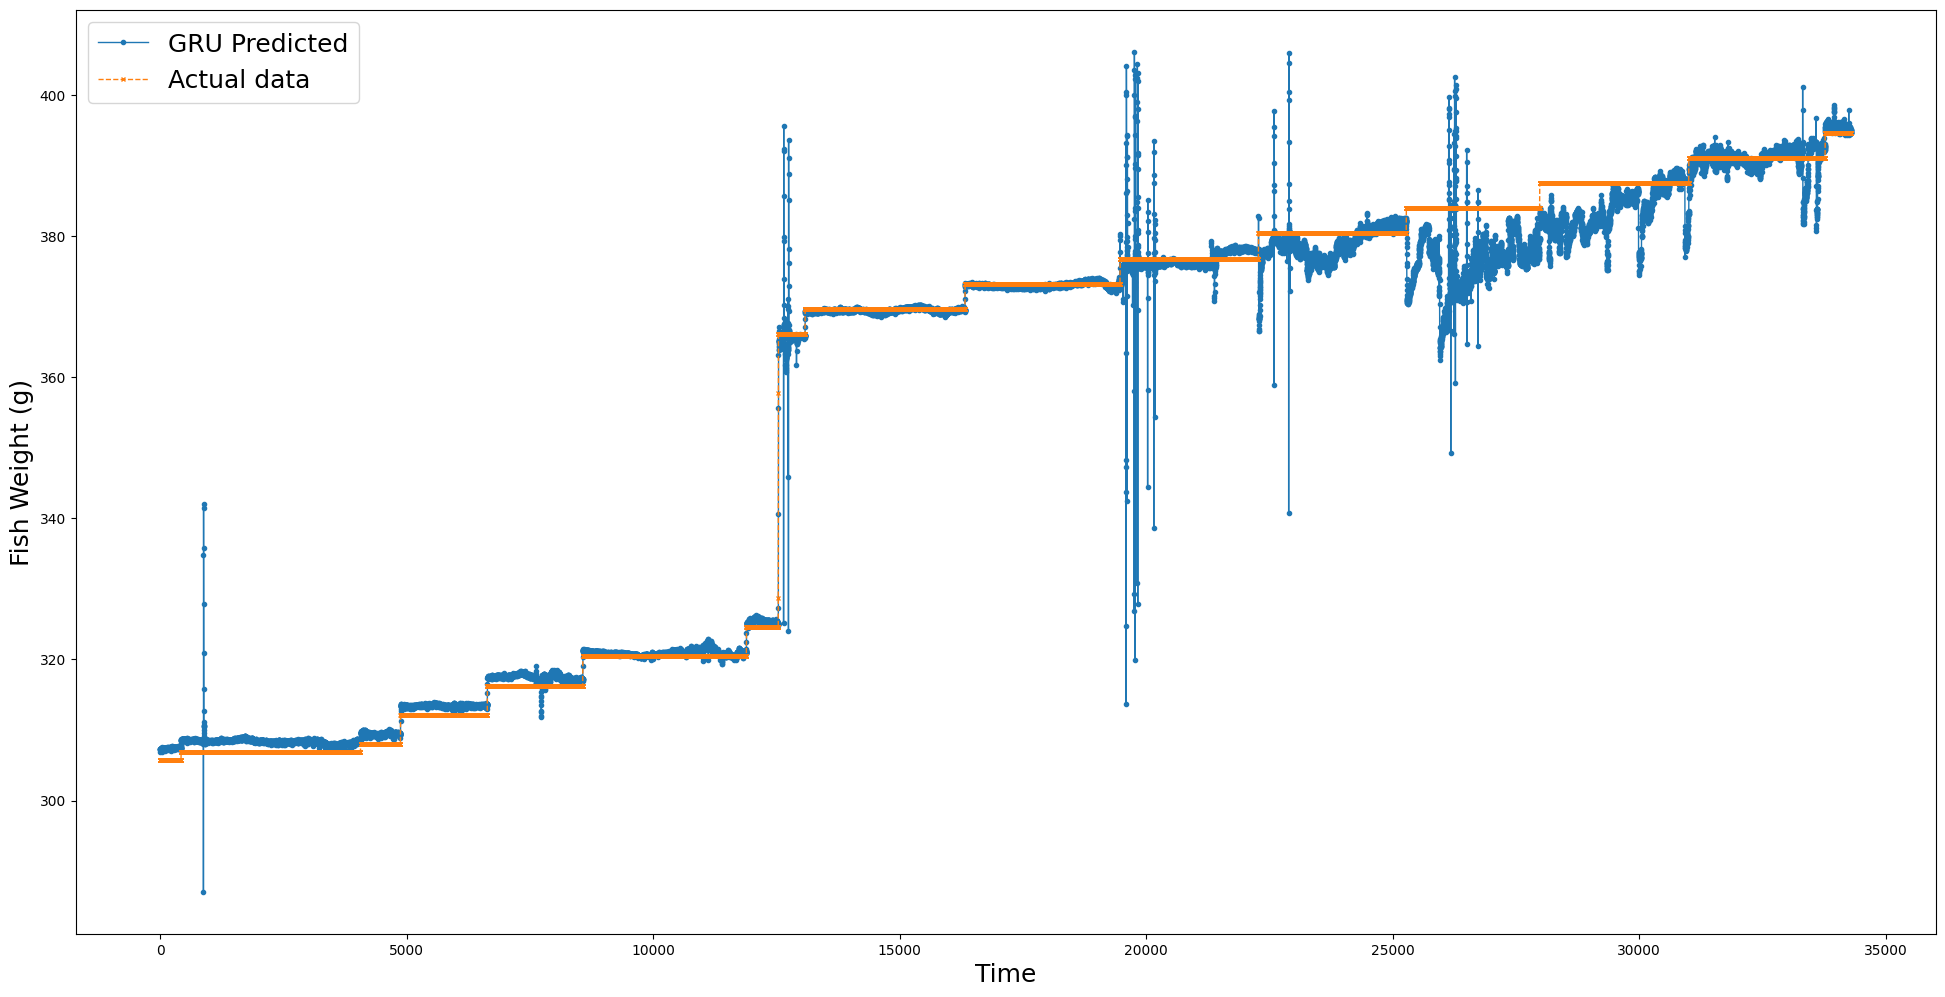

In [8]:
# plt.style.use('fivethirtyeight')
# Now let's create a plot suitable for black and white printing
plt.figure(figsize=(24,12))

# Use different line styles for predicted and actual. Increase line width for visibility.
plt.plot(predictions, linestyle='-', marker='o', linewidth=1, label='GRU Predicted', markersize=3)
plt.plot(output_scaler.inverse_transform(y_test), linestyle='--', marker='x', linewidth=1, label='Actual data', markersize=3)

# Setting up title and labels with increased font size for readability
# plt.title('Fish Growth Prediction Model', fontsize=22)
plt.xlabel('Time', fontsize=18)
plt.ylabel('Fish Weight (g)', fontsize=18)

# Adding a legend with a larger font size
plt.legend(fontsize=18)

# Save the figure with high resolution
plt.savefig('GRU_Prediction.png', dpi=800, format='png')

# Show the plot
plt.show()

In [9]:
test_results_lstm = pd.DataFrame(data={'Model Predictions':predictions[:, 0], 'Actuals':output_scaler.inverse_transform(y_test)[:, 0]})
test_results_lstm

,Model Predictions,Actuals
0,307.260834,305.80
1,307.225983,305.80
2,306.927673,305.80
3,307.260986,305.80
4,307.279541,305.80
...,...,...
34293,394.862579,394.66
34294,394.602722,394.66
34295,394.977905,394.66
34296,394.636963,394.66


In [10]:
test_results_lstm.to_csv("test_results_lstm.csv")

### Load LSTM Model

In [11]:
model_lstm = load_model('/kaggle/input/rnnmodel/best_model7.h5')

In [12]:
predictions1 = model_lstm.predict(X_test)
predictions1 = output_scaler.inverse_transform(predictions1)
predictions1

1072/1072 [==============================] - 8s 7ms/step


array([[305.65918],
       [305.66144],
       [305.65863],
       ...,
       [354.39398],
       [354.03244],
       [353.53006]], dtype=float32)

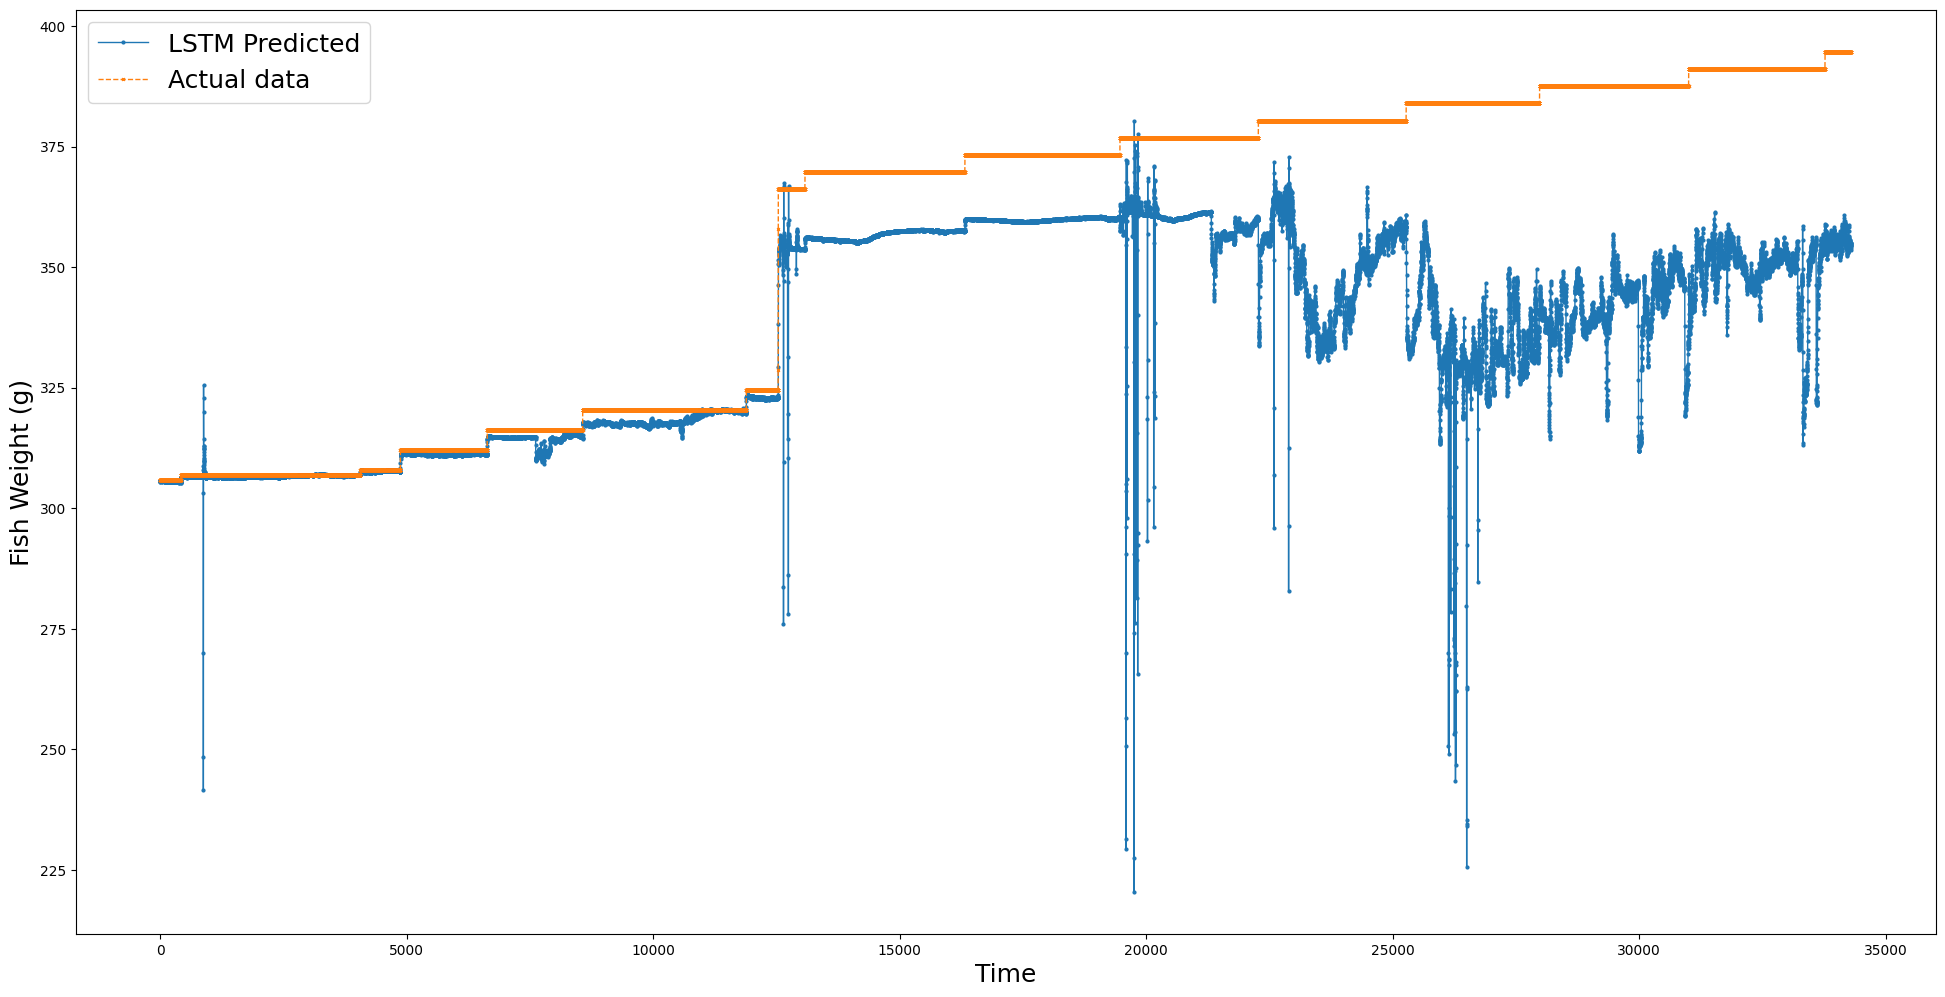

In [13]:
# plt.style.use('fivethirtyeight')
# Now let's create a plot suitable for black and white printing
plt.figure(figsize=(24,12))

# Use different line styles for predicted and actual. Increase line width for visibility.
plt.plot(predictions1, linestyle='-', marker='o', linewidth=1, label='LSTM Predicted', markersize=2)
plt.plot(output_scaler.inverse_transform(y_test), linestyle='--', marker='x', linewidth=1, label='Actual data', markersize=2)

# Setting up title and labels with increased font size for readability
# plt.title('Fish Growth Prediction Model', fontsize=22)
plt.xlabel('Time', fontsize=18)
plt.ylabel('Fish Weight (g)', fontsize=18)

# Adding a legend with a larger font size
plt.legend(fontsize=18)

# Save the figure with high resolution
plt.savefig('LSTM_Prediction.png', dpi=800, format='png')

# Show the plot
plt.show()


In [14]:
test_results_lstm = pd.DataFrame(data={'Model Predictions':predictions1[:, 0], 'Actuals':output_scaler.inverse_transform(y_test)[:, 0]})
test_results_lstm

,Model Predictions,Actuals
0,305.659180,305.80
1,305.661438,305.80
2,305.658630,305.80
3,305.644501,305.80
4,305.578766,305.80
...,...,...
34293,354.348419,394.66
34294,354.629303,394.66
34295,354.393982,394.66
34296,354.032440,394.66
